In [60]:
from NN import LNN_Regression
import numpy as np

'Für die Parameter m=2 und k=0.5 Trainieren wir das LNN um folgende Dynamik zu lernen'
'qdd(t) + 1/4 q(t) = 0 -> q(t) = 2qd(0) sin(t/2)+ q(0)cos(t/2)'
'Wir testen am Ende auf dem Startpunkt q(0)= 0 und qd(0) = 1'

np.random.seed(42)
h = 20
model = LNN_Regression(layers=h)
model.read_data("spring_data_no_control.csv")

_, _, _, H = model.L_derivatives(model.X)
print(f"H_min={H.min():.4f}  H_mean={H.mean():.4f}  neg={np.mean(H<=0):.4f}")
print(f"Loss: {model.loss():.4e}")
print("K =", model.K, "M =", model.M, "N =", model.N)
print("Loss:", model.loss())

Episodes = 10000
for epoch in range(Episodes):
    model.train_step(1e-4)
    if epoch % int(Episodes/10) == 0:
        print(f"Epoch {epoch:4d}  Loss = {model.loss():.6f}")

# nach dem Training → NEU berechnen
_, _, _, H_after = model.L_derivatives(model.X)
print(f"Nachher: H_min={H_after.min():.4f}  H_mean={H_after.mean():.4f}")

H_min=2.0003  H_mean=2.2389  neg=0.0000
Loss: 5.3523e+00
K = 25000 M = 50 N = 500
Loss: 5.352319056186875
Epoch    0  Loss = 4.799161
Epoch 1000  Loss = 0.180401
Epoch 2000  Loss = 0.137977
Epoch 3000  Loss = 0.125686
Epoch 4000  Loss = 0.121054
Epoch 5000  Loss = 0.119132
Epoch 6000  Loss = 0.118297
Epoch 7000  Loss = 0.117927
Epoch 8000  Loss = 0.117760
Epoch 9000  Loss = 0.117684
Nachher: H_min=3.5123  H_mean=4.1900


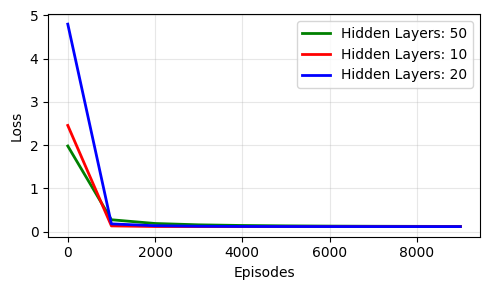

In [63]:
import matplotlib.pyplot as plt
import numpy as np

epochs = [0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000]
losses_50 = [1.980901, 0.275978, 0.189517, 0.158605, 0.143349,
          0.134643, 0.129254, 0.125745, 0.123381, 0.121750]

losses_10 = [2.456804, 0.133671, 0.119895, 0.118016, 0.117694,
          0.117633, 0.117621, 0.117619, 0.117618, 0.117618]

losses_20 = [4.799161, 0.180401, 0.137977, 0.125686, 0.121054, 0.119132,
             0.118297, 0.117927, 0.117760 , 0.117684]

fig, ax = plt.subplots(figsize=(5, 3))

ax.plot(epochs, losses_50, 'g-', linewidth=2, markersize=6, label = 'Hidden Layers: 50')
ax.plot(epochs, losses_10, 'r-', linewidth=2, markersize=6, label = 'Hidden Layers: 10')
ax.plot(epochs, losses_20, 'b-', linewidth=2, markersize=6, label = 'Hidden Layers: 20')
ax.set_xlabel('Episodes')
ax.set_ylabel('Loss')
ax.legend()
#ax.set_title('Trainingsverlauf LNN mit $u=0$-Daten')
ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.savefig("loss_u0.pdf")
plt.show()

In [1]:
import matplotlib.pyplot as plt
import numpy as np

omega = 0.5
def q_analytic(t, q0, qdot0):
    return q0*np.cos(omega*t) + (qdot0/omega)*np.sin(omega*t)

def qddot_learned(q, qdot, u=0):
    dLdq, _, C, H = model.forward(q, qdot)
    return (dLdq[0] - C[0]*qdot + u) / H[0]

def rk4_step(q, qdot, u, h):
    k1_q, k1_qd = qdot, qddot_learned(q, qdot, u)
    k2_q, k2_qd = qdot+h/2*k1_qd, qddot_learned(q+h/2*k1_q, qdot+h/2*k1_qd, u)
    k3_q, k3_qd = qdot+h/2*k2_qd, qddot_learned(q+h/2*k2_q, qdot+h/2*k2_qd, u)
    k4_q, k4_qd = qdot+h*k3_qd,   qddot_learned(q+h*k3_q,   qdot+h*k3_qd,   u)
    return q+h/6*(k1_q+2*k2_q+2*k3_q+k4_q), qdot+h/6*(k1_qd+2*k2_qd+2*k3_qd+k4_qd)

h = 0.01
T_end = 14.0
t_grid = np.arange(0, T_end + h, h)

q0, qdot0 = 0.0, 1.0

q_l = np.zeros(len(t_grid))
qd_l = np.zeros(len(t_grid))
q_l[0], qd_l[0] = q0, qdot0
for i in range(len(t_grid)-1):
    q_l[i+1], qd_l[i+1] = rk4_step(q_l[i], qd_l[i], 0.0, h)

q_true  = q_analytic(t_grid, q0, qdot0)
qd_true = -q0*omega*np.sin(omega*t_grid) + qdot0*np.cos(omega*t_grid)

fig, ax = plt.subplots(1, 2, figsize=(10, 6))

# Analytisch
ax[0].plot(q_true, qd_true, 'k-', linewidth=2, label='Analytisch')
ax[0].set_xlabel('$q$')
ax[0].set_ylabel('$\\dot q$')
ax[0].set_title('Analytic Solutions')
ax[0].grid(alpha=0.3)
ax[0].set_aspect('equal')

# LNN
ax[1].plot(q_l, qd_l, 'r-', linewidth=2, label='LNN')
ax[1].set_xlabel('$q$')
ax[1].set_ylabel('$\\dot q$')
ax[1].set_title('LNN Prediction')
ax[1].grid(alpha=0.3)
ax[1].set_aspect('equal')

# Gemeinsame Grenzen für beide
xlim = (-2.5, 2.5)
ylim = (-1.5, 1.5)
ax[0].set_xlim(xlim); ax[0].set_ylim(ylim)
ax[1].set_xlim(xlim); ax[1].set_ylim(ylim)

plt.tight_layout()
plt.show()

print("q_l   range:", q_l.min(), q_l.max())
print("qd_l  range:", qd_l.min(), qd_l.max())

NameError: name 'model' is not defined

H_min=0.0201  H_mean=2.0967  neg=0.0000
Loss: 1.0786e+02
Nachher: H_min=-3.2620  H_mean=3.6009, neg=0.0640, Gradientennorm = 4062397551.153868
Loss: 3.6347e+04


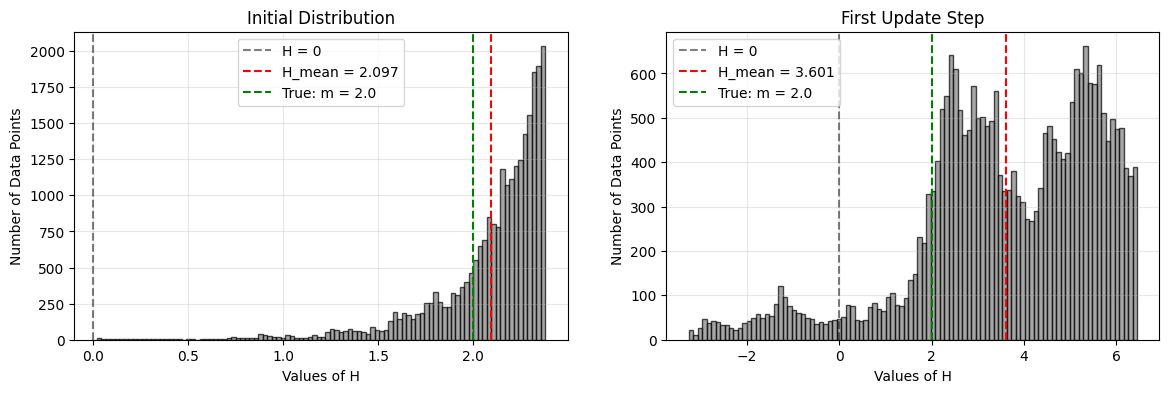

In [66]:
from NN import LNN_Regression
import numpy as np
import matplotlib.pyplot as plt

'Für die Parameter m=2 und k=0.5 Trainieren wir das LNN um folgende Dynamik zu lernen'
'qdd(t) + 1/4 q(t) = 1/2 u(t)'
'Wir testen am Ende auf dem Startpunkt q(0)= 0 und qd(0) = 1'

np.random.seed(42)
h = 20
model_with_control = LNN_Regression(layers=h)
model_with_control.read_data("spring_data_with_control.csv")

_, _, _, H = model_with_control.L_derivatives(model_with_control.X)
print(f"H_min={H.min():.4f}  H_mean={H.mean():.4f}  neg={np.mean(H<=0):.4f}")
print(f"Loss: {model_with_control.loss():.4e}")
#print("Loss:", model_with_control.loss())

H_old = H.flatten()   # (1, K) -> (K,)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 1. Histogramm
axes[0].hist(H_old, bins=100, color='grey', edgecolor='black', alpha=0.7)
axes[0].axvline(0, color='k', linestyle='--', alpha=0.5, label='H = 0')
axes[0].axvline(H_old.mean(), color='r', linestyle='--', label=f'H_mean = {H.mean():.3f}')
axes[0].axvline(2.0, color='g', linestyle='--', label='True: m = 2.0')
axes[0].set_xlabel('Values of H')
axes[0].set_ylabel('Number of Data Points')
axes[0].set_title('Initial Distribution')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Ein Update Schritt:
model_with_control.train_step(1e-5)
gW1, gb1 , gWN = model_with_control.gradient_descent()

# nach dem Training → NEU berechnen
_, _, _, H_after = model_with_control.L_derivatives(model_with_control.X)
print(f"Nachher: H_min={H_after.min():.4f}  H_mean={H_after.mean():.4f}, neg={np.mean(H_after<=0):.4f}, Gradientennorm = {np.sqrt(np.sum(gW1**2))}")
print(f"Loss: {model_with_control.loss():.4e}")
#print("Loss:", model_with_control.loss())

H_after = H_after.flatten()

# 2. Histogramm
axes[1].hist(H_after, bins=100, color='grey', edgecolor='black', alpha=0.7)
axes[1].axvline(0, color='k', linestyle='--', alpha=0.5, label='H = 0')
axes[1].axvline(H_after.mean(), color='r', linestyle='--', label=f'H_mean = {H_after.mean():.3f}')
axes[1].axvline(2.0, color='g', linestyle='--', label='True: m = 2.0')
axes[1].set_xlabel('Values of H')
axes[1].set_ylabel('Number of Data Points')
axes[1].set_title('First Update Step')
axes[1].legend()
axes[1].grid(alpha=0.3)